In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
ds = pd.read_csv('fifa_world_cup_2026_player_performance.csv')
ds['is_star'] = (ds['player_rating'] >= 8.0).astype(int)
target = 'is_star'

X = ds.drop(columns=['player_id', 'player_name', 'player_rating', target])
y = ds[target]

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

final_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # ('classifier', RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0, n_jobs=-1))
    ('classifier', SVC(kernel='rbf', degree=3, random_state=0, gamma='auto', class_weight='balanced'))
])

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

final_model_pipeline.fit(X_train, y_train)
y_pred = final_model_pipeline.predict(X_test)

Random Forest Accuracy: 99.11%

Classification Report:
                precision    recall  f1-score   support

Average Player       0.99      1.00      1.00     13529
   Star Player       0.50      0.01      0.02       121

      accuracy                           0.99     13650
     macro avg       0.75      0.50      0.51     13650
  weighted avg       0.99      0.99      0.99     13650



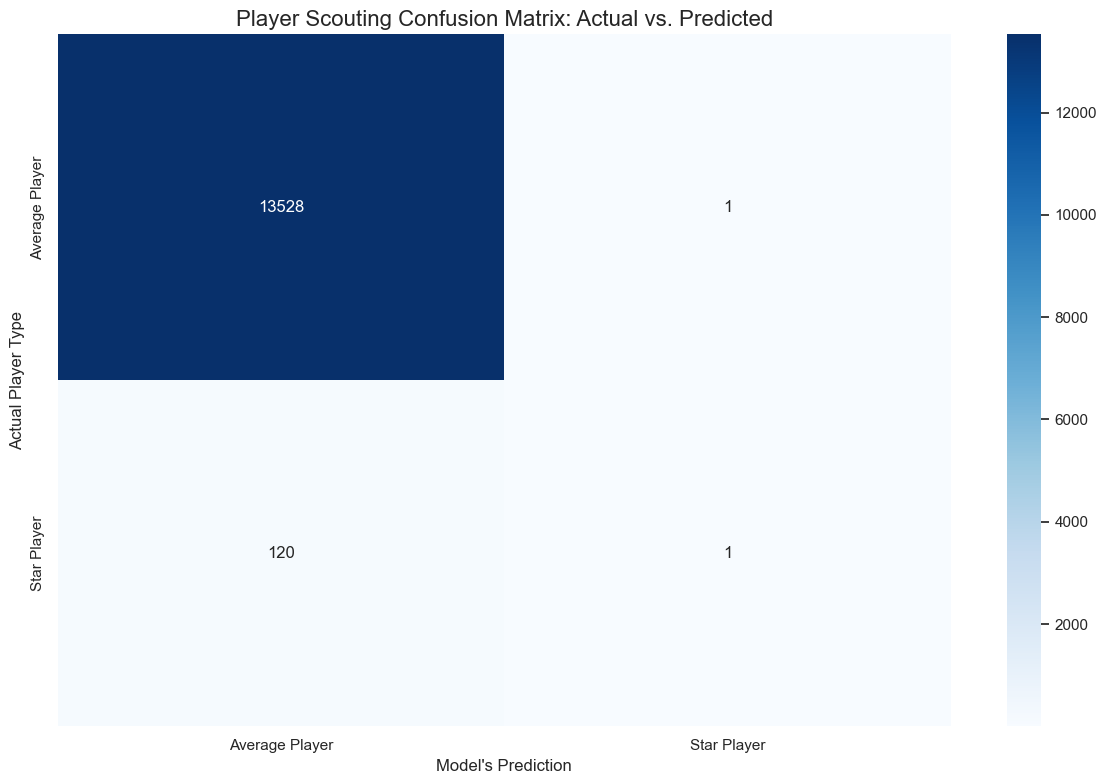

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = ['Average Player', 'Star Player']

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Player Scouting Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Player Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

SVC Accuracy: 94.82%

Classification Report:
                precision    recall  f1-score   support

Average Player       1.00      0.95      0.97     13529
   Star Player       0.14      0.98      0.25       121

      accuracy                           0.95     13650
     macro avg       0.57      0.96      0.61     13650
  weighted avg       0.99      0.95      0.97     13650



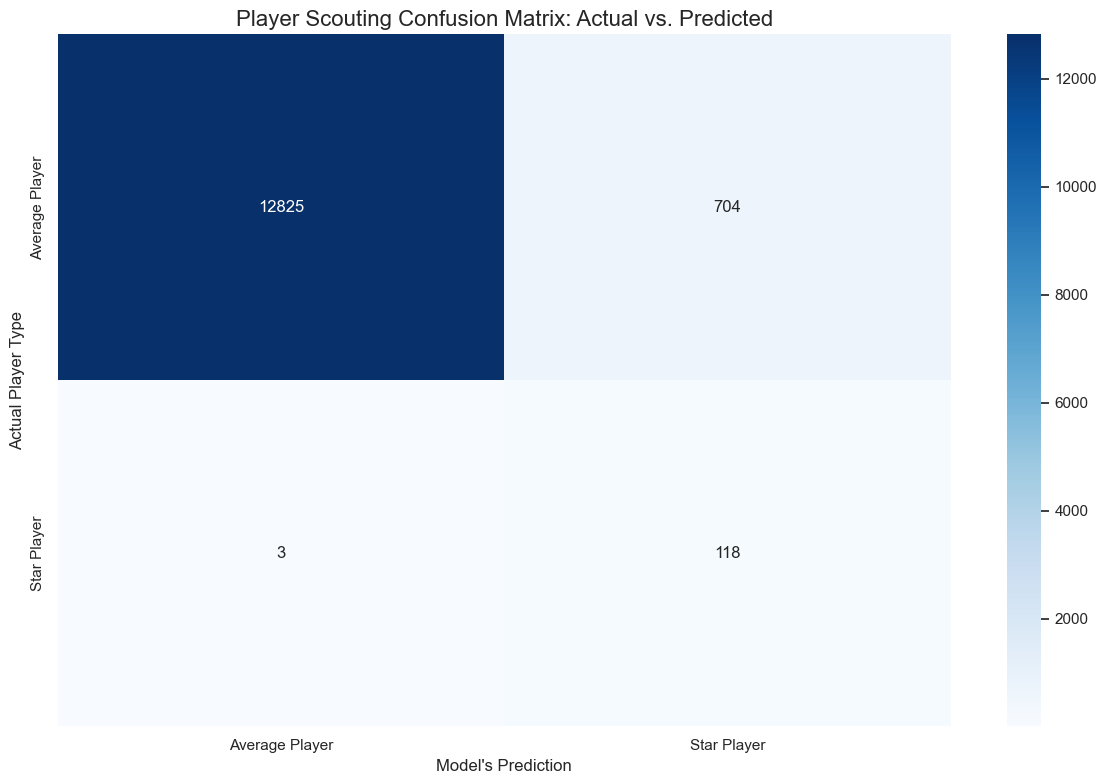

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = ['Average Player', 'Star Player']

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"SVC Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Player Scouting Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Player Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# 1. Define the grid using the EXACT name of your final step ('classifier') + '__'
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1],
    "classifier__class_weight": [None, "balanced"]
}

# 2. Wrap your ENTIRE custom pipeline in the GridSearchCV
grid_search = GridSearchCV(
    estimator=final_model_pipeline, # <-- Your pipeline goes here!
    param_grid=param_grid, 
    cv=5, 
    scoring="f1_macro",
    n_jobs=-1 # Uses all your computer's cores to speed up the massive test
)

# 3. Train the Grid Search
# This will push X_train through your preprocessor and test EVERY combination of the SVC parameters!
grid_search.fit(X_train, y_train)

# 4. Print the winning combination!
print("Best Parameters Found:", grid_search.best_params_)

# 5. Make predictions using the winning model
y_pred_tuned = grid_search.predict(X_test)